# Mini-Project 1: Weather Forecast with Python Web APIs

Data sources: Open-Meteo (geocoding and forecast) and MET Norway Locationforecast 2.0.

In [1]:
# --- CONFIGURATION: the only cell to edit ---
import os

LOCATION = "MUKONO"  # city to forecast; change if you like
COUNTRY_CODE = "UG"  # ISO country code to narrow the search; None = worldwide
LOCATION_CHOICE = 0  # number of the place to use, from the candidate list below
FORECAST_DAYS = 7    # number of days to forecast (1-16)

PLACEHOLDER_EMAIL = "YOUR_UNIVERSITY_EMAIL"
CONTACT_EMAIL = os.environ.get("WEATHER_CONTACT_EMAIL", PLACEHOLDER_EMAIL)
USER_AGENT = f"oop-python-assignment2/1.0 ({CONTACT_EMAIL})"

if CONTACT_EMAIL == PLACEHOLDER_EMAIL:
    print("WARNING: set WEATHER_CONTACT_EMAIL before calling the APIs.")
print("Location:", LOCATION)
print("Contact email configured:", CONTACT_EMAIL != PLACEHOLDER_EMAIL)

Location: MUKONO
Contact email configured: True


In [2]:
import json
import urllib.parse
import urllib.request

GEOCODING_URL = "https://geocoding-api.open-meteo.com/v1/search"

query = urllib.parse.urlencode(
    {"name": LOCATION, "count": 5, "language": "en", "format": "json"}
)
url = f"{GEOCODING_URL}?{query}"
req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})

with urllib.request.urlopen(req, timeout=10) as resp:
    status_urllib = resp.status
    body = resp.read().decode("utf-8")

data_urllib = json.loads(body)
print("URL:", url)
print("Status:", status_urllib)
for place in data_urllib.get("results", []):
    print(place["name"], "|", place.get("admin1"), "|",
          place.get("country"), "|", place["latitude"], place["longitude"])

URL: https://geocoding-api.open-meteo.com/v1/search?name=MUKONO&count=5&language=en&format=json
Status: 200
Mukono | Central Region | Uganda | 0.35333 32.75528
Mukono | Northern Province | Rwanda | -1.4551 30.0149
Mokono | Kasai | Democratic Republic of Congo | -7.28013 21.62154
Mukono | Central Region | Uganda | 0.27276 32.46589
Mukono | Western Province | Zambia | -14.6 24.25


In [3]:
import requests

resp_requests = requests.get(
    GEOCODING_URL,
    params={"name": LOCATION, "count": 5, "language": "en", "format": "json"},
    headers={"User-Agent": USER_AGENT},
    timeout=10,
)
data_requests = resp_requests.json()

print("URL built by requests:", resp_requests.url)
print("Status:", resp_requests.status_code)
print("Number of results:", len(data_requests.get("results", [])))
print("Same results as urllib:",
      data_requests.get("results") == data_urllib.get("results"))

URL built by requests: https://geocoding-api.open-meteo.com/v1/search?name=MUKONO&count=5&language=en&format=json
Status: 200
Number of results: 5
Same results as urllib: True


##  urllib vs requests

| Aspect | urllib (standard library) | requests |
|---|---|---|
| Code length | 6 steps. urlencode, then Request, urlopen, read, decode and json.loads | 2 steps. requests.get(...) and .json() |
| Error handling | raises HTTPError automatically for 4xx and 5xx responses, and URLError for network failures. | does not raise for 4xx or 5xx, so you must call raise_for_status(). Network failures raise ConnectionError or Timeout, both under RequestException |
| Header control | you must build a Request object to add headers. | pass a headers= dictionary directly. | 
| Encoding | returns raw bytes. The code decoded them manually, assuming UTF-8. | reads charset=utf-8 from the Content-Type header and decodes automatically |

**Conclusion:**  Both methods gave the same results for Mukono. I'll use `requests` for the rest of the project because it's shorter and handles headers, parameters and encoding for me. The catch is that it doesn't flag 4xx/5xx errors on its own, so I'll need `raise_for_status()`. `urllib` is still handy when you can't install extra packages.

In [4]:
print("Status code:", resp_requests.status_code)
print("Content-Type:", resp_requests.headers.get("Content-Type"))
print("Response time (s):", round(resp_requests.elapsed.total_seconds(), 3))

Status code: 200
Content-Type: application/json; charset=utf-8
Response time (s): 0.824


## Part B: Forecast retrieval and display

In [5]:
%load_ext autoreload
%autoreload 2

import os
import sys

PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.weather import parse_geocoding_results

In [6]:
candidates = parse_geocoding_results(data_requests)
for number, place in enumerate(candidates):
    print(number, place)

print("No-results case:", parse_geocoding_results({}))


0 {'name': 'Mukono', 'admin1': 'Central Region', 'country': 'Uganda', 'latitude': 0.35333, 'longitude': 32.75528, 'timezone': 'Africa/Kampala', 'population': 191300}
1 {'name': 'Mukono', 'admin1': 'Northern Province', 'country': 'Rwanda', 'latitude': -1.4551, 'longitude': 30.0149, 'timezone': 'Africa/Kigali', 'population': None}
2 {'name': 'Mokono', 'admin1': 'Kasai', 'country': 'Democratic Republic of Congo', 'latitude': -7.28013, 'longitude': 21.62154, 'timezone': 'Africa/Lubumbashi', 'population': None}
3 {'name': 'Mukono', 'admin1': 'Central Region', 'country': 'Uganda', 'latitude': 0.27276, 'longitude': 32.46589, 'timezone': 'Africa/Kampala', 'population': None}
4 {'name': 'Mukono', 'admin1': 'Western Province', 'country': 'Zambia', 'latitude': -14.6, 'longitude': 24.25, 'timezone': 'Africa/Lusaka', 'population': None}
No-results case: []


In [7]:
from src.weather import geocode

candidates = geocode(LOCATION, USER_AGENT, country_code=COUNTRY_CODE)
for number, place in enumerate(candidates):
    print(number, place["name"], "|", place["admin1"], "|",
          place["country"], "| population:", place["population"])

0 Mukono | Central Region | Uganda | population: 191300
1 Mukono | Central Region | Uganda | population: None
2 Mukono Landing | Central Region | Uganda | population: None


In [8]:
from src.weather import choose_location

location = choose_location(candidates, LOCATION_CHOICE)
print(f"Using: {location['name']}, {location['admin1']}, {location['country']} "
      f"({location['latitude']}, {location['longitude']}), "
      f"timezone {location['timezone']}")

Using: Mukono, Central Region, Uganda (0.35333, 32.75528), timezone Africa/Kampala


In [9]:
from src.weather import get_forecast

forecast = get_forecast(location["latitude"], location["longitude"],
                        FORECAST_DAYS, USER_AGENT,
                        timezone=location["timezone"])
print("Timezone used:", forecast["timezone"])
print("Units:", forecast["daily_units"])
print("Dates:", forecast["daily"]["time"])

Timezone used: Africa/Kampala
Units: {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h', 'weather_code': 'wmo code'}
Dates: ['2026-10-12', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18']


In [10]:
from src.weather import forecast_to_dataframe

forecast_df = forecast_to_dataframe(forecast)
forecast_df

,Date,Weather,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind speed (km/h)
0,2026-10-12,Slight rain showers,25.7,18.8,4.5,14.8
1,2026-10-13,Slight or moderate thunderstorm,26.3,18.5,11.9,17.0
2,2026-10-14,Slight rain showers,27.4,19.0,1.8,10.4
3,2026-10-15,Moderate rain showers,26.0,18.0,4.8,8.1
4,2026-10-16,Moderate rain showers,24.2,18.3,11.6,15.9
5,2026-10-17,Slight rain showers,25.0,18.7,16.8,5.8
6,2026-10-18,Moderate rain showers,25.8,19.0,9.3,7.7


In [11]:
forecast_table = (
    forecast_df.style
    .format({"Date": "{:%a %d %b}"}, precision=1)
    .hide(axis="index")
    .set_caption(
        f"{FORECAST_DAYS}-day forecast for {location['name']}, "
        f"{location['country']}. Weather data by Open-Meteo.com"
    )
)
forecast_table

Date,Weather,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind speed (km/h)
Mon 12 Oct,Slight rain showers,25.7,18.8,4.5,14.8
Tue 13 Oct,Slight or moderate thunderstorm,26.3,18.5,11.9,17.0
Wed 14 Oct,Slight rain showers,27.4,19.0,1.8,10.4
Thu 15 Oct,Moderate rain showers,26.0,18.0,4.8,8.1
Fri 16 Oct,Moderate rain showers,24.2,18.3,11.6,15.9
Sat 17 Oct,Slight rain showers,25.0,18.7,16.8,5.8
Sun 18 Oct,Moderate rain showers,25.8,19.0,9.3,7.7


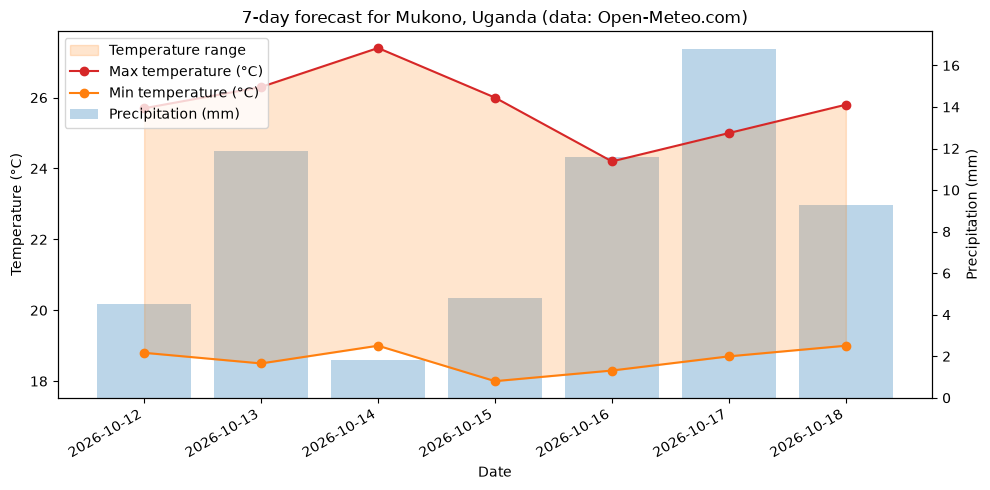

In [12]:
import matplotlib.pyplot as plt
from src.weather import plot_forecast

fig = plot_forecast(
    forecast_df,
    f"{FORECAST_DAYS}-day forecast for {location['name']}, "
    f"{location['country']} (data: Open-Meteo.com)",
)
plt.show()

In [13]:
from src.weather import summarise_forecast

print(summarise_forecast(forecast_df,
                         f"{location['name']}, {location['country']}"))

Forecast for Mukono, Uganda, Mon 12 Oct to Sun 18 Oct:
- Temperatures from 18.0 to 27.4 °C; warmest day Wed 14 Oct.
- Rain expected on 7 of 7 days, 60.7 mm in total; wettest day Sat 17 Oct (16.8 mm).
- Strongest wind 17.0 km/h on Tue 13 Oct.
- Most common conditions: Moderate rain showers.


## Part C: Robustness

Each demo below deliberately breaks one input and shows the exception raised, its message, and how long it took (which shows the retry backoff).

In [14]:
import time
from src.weather import (FORECAST_URL, LocationNotFoundError,
                         WeatherAPIError, fetch_json)


def demo(label: str, action) -> None:
    """Run action() and report the exception it raises, with timing."""
    start = time.perf_counter()
    try:
        action()
        print(f"{label}: no error raised")
    except Exception as error:
        elapsed = time.perf_counter() - start
        print(f"{label}: {type(error).__name__} after {elapsed:.1f} s")
        print(f"  {error}\n")

In [15]:
MUKONO_PARAMS = {"latitude": 0.35, "longitude": 32.76,
                 "daily": "temperature_2m_max"}

demo("Invalid city",
     lambda: choose_location(geocode("Zzqxwv", USER_AGENT), 0))

demo("Invalid latitude (checked locally)",
     lambda: get_forecast(123.0, 32.76, 7, USER_AGENT))

demo("Invalid latitude (sent to the API)",
     lambda: fetch_json(FORECAST_URL, {**MUKONO_PARAMS, "latitude": 123.0},
                        USER_AGENT))

demo("No network (simulated)",
     lambda: fetch_json("http://localhost:9/v1/forecast", MUKONO_PARAMS,
                        USER_AGENT, max_retries=2, backoff=0.5))

demo("Tiny timeout",
     lambda: fetch_json(FORECAST_URL, MUKONO_PARAMS, USER_AGENT,
                        timeout=0.001, max_retries=2, backoff=0.5))

Invalid city: LocationNotFoundError after 0.9 s
  No places matched the search.

Invalid latitude (checked locally): ValueError after 0.0 s
  Latitude must be between -90 and 90, got 123.0.



Invalid latitude (sent to the API): WeatherAPIError after 0.8 s
  https://api.open-meteo.com/v1/forecast returned HTTP 400: {"reason":"Latitude must be in range of -90 to 90°. Given: 123.0.","error":true}



No network (simulated): WeatherAPIError after 13.8 s
  http://localhost:9/v1/forecast failed after 3 attempts: HTTPConnectionPool(host='localhost', port=9): Max retries exceeded with url: /v1/forecast?latitude=0.35&longitude=32.76&daily=temperature_2m_max (Caused by NewConnectionError("HTTPConnection(host='localhost', port=9): Failed to establish a new connection: [WinError 10061] No connection could be made because the target machine actively refused it"))



Tiny timeout: WeatherAPIError after 1.5 s
  https://api.open-meteo.com/v1/forecast failed after 3 attempts: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=0.35&longitude=32.76&daily=temperature_2m_max (Caused by ConnectTimeoutError(<HTTPSConnection(host='api.open-meteo.com', port=443) at 0x20f92f116d0>, 'Connection to api.open-meteo.com timed out. (connect timeout=0.001)'))



In [16]:
from src.weather import compare_forecasts, get_met_forecast, met_to_daily_dataframe

met_raw = get_met_forecast(location["latitude"], location["longitude"], USER_AGENT)
met_df = met_to_daily_dataframe(met_raw, location["timezone"])
comparison = compare_forecasts(forecast_df, met_df)

(comparison.style
 .format({"Date": "{:%a %d %b}"}, precision=1)
 .hide(axis="index")
 .set_caption("Open-Meteo vs MET Norway. Data: Open-Meteo.com; "
              "MET Norway (CC BY 4.0)"))

Date,Max temperature (°C) [Open-Meteo],Min temperature (°C) [Open-Meteo],Precipitation (mm) [Open-Meteo],Max temperature (°C) [MET],Min temperature (°C) [MET],Precipitation (mm) [MET],Max temperature (°C) difference,Min temperature (°C) difference,Precipitation (mm) difference
Mon 12 Oct,25.7,18.8,4.5,19.2,19.2,0.0,6.5,-0.4,4.5
Tue 13 Oct,26.3,18.5,11.9,26.3,18.7,14.7,0.0,-0.2,-2.8
Wed 14 Oct,27.4,19.0,1.8,27.4,19.2,0.7,0.0,-0.2,1.1
Thu 15 Oct,26.0,18.0,4.8,26.3,18.1,6.8,-0.3,-0.1,-2.0
Fri 16 Oct,24.2,18.3,11.6,23.1,19.2,24.2,1.1,-0.9,-12.6
Sat 17 Oct,25.0,18.7,16.8,24.6,19.2,13.4,0.4,-0.5,3.4
Sun 18 Oct,25.8,19.0,9.3,22.6,18.3,12.8,3.2,0.7,-3.5


In [17]:
met_df[["Date", "Hourly samples"]]

,Date,Hourly samples
0,2026-10-12,1
1,2026-10-13,24
2,2026-10-14,24
3,2026-10-15,17
4,2026-10-16,4
5,2026-10-17,4
6,2026-10-18,4
7,2026-10-19,4
8,2026-10-20,4
9,2026-10-21,4


In [18]:
met_df[["Date", "Hourly samples"]]

,Date,Hourly samples
0,2026-10-12,1
1,2026-10-13,24
2,2026-10-14,24
3,2026-10-15,17
4,2026-10-16,4
5,2026-10-17,4
6,2026-10-18,4
7,2026-10-19,4
8,2026-10-20,4
9,2026-10-21,4


In [19]:
# ONE-OFF: save real API responses as fixed samples for the offline tests.
# Run once, check the files, then DELETE this cell.
import json

samples = {
    "sample_geocoding.json": data_requests,
    "sample_geocoding_empty.json": fetch_json(
        GEOCODING_URL,
        {"name": "Zzqxwv", "count": 5, "language": "en", "format": "json"},
        USER_AGENT),
    "sample_forecast.json": forecast,
    "sample_met.json": met_raw,
}
for filename, content in samples.items():
    path = os.path.join(PROJECT_ROOT, "data", filename)
    with open(path, "w", encoding="utf-8") as file:
        json.dump(content, file, indent=2, ensure_ascii=False)
    print("Saved", filename, os.path.getsize(path), "bytes")

Saved sample_geocoding.json 2478 bytes
Saved sample_geocoding_empty.json 38 bytes
Saved sample_forecast.json 1239 bytes
Saved sample_met.json 83549 bytes


## Part D: Report
The only manual input is the configuration cell, which contains the location identifier: the place name (LOCATION), optionally with a country code to narrow the search (COUNTRY_CODE), the number of the chosen candidate (LOCATION_CHOICE) and the number of forecast days. The contact email is not entered into the notebook, but is read from the WEATHER_CONTACT_EMAIL environment variable and added into the User-Agent header, so that it is never stored in shared code.

The place name is first geocoded. geocode() sends it to the Open-Meteo Geocoding API and returns a list of candidate places, since a single name can match multiple locations. choose_location() then selects the candidate given by LOCATION_CHOICE, which supplies the latitude, longitude and time zone. These parameters are passed to get_forecast(), which requests the daily forecast. forecast_to_dataframe() converts the JSON into a pandas DataFrame with units and readable weather descriptions, which is displayed as a table, a chart and a text summary. In parallel, the same coordinates are sent to MET Norway, and its hourly data is converted into daily values for comparison.

Each request passes through one function, fetch_json(), which is responsible for error handling: it has a timeout, checks the status code and retries temporary failures. Keeping this in one place means that all API calls are consistently handled.

Fetching and parsing are separated. Fetching deals with network connections and parsing deals with restructuring the raw data. This separation means that the parsing functions can be tested offline with saved JSON files.

```
Configuration cell: LOCATION, COUNTRY_CODE, LOCATION_CHOICE, FORECAST_DAYS
        |                     (email read from WEATHER_CONTACT_EMAIL)
        v
geocode() --> fetch_json() --> Open-Meteo Geocoding API
        |     (timeout, retries, raise_for_status, WeatherAPIError)
        v
parse_geocoding_results() --> candidate list --> choose_location()
        |
        v
get_forecast(lat, lon, days, timezone) --> fetch_json() --> Open-Meteo Forecast API
        |
        v
forecast_to_dataframe()  (units from daily_units, describe_weather_code)
        |
        +--> formatted table    +--> chart    +--> text summary
        |
get_met_forecast() --> fetch_json() --> MET Norway Locationforecast 2.0
        |
        v
met_to_daily_dataframe() (UTC -> local days) --> compare_forecasts()
```

**2. Licensing and usage terms**
Both providers license their data under Creative Commons Attribution 4.0 (CC BY 4.0), requiring any display of the data to attribute it to the source. This is why the table, chart and comparison in this notebook credit Open-Meteo.com and MET Norway. The location data behind Open-Meteo's geocoding comes from GeoNames, which should also be credited.

The free API from Open-Meteo is for non-commercial use only, with limits of less than 10,000 calls per day, 5,000 per hour and 600 per minute. A company could not use the free API to make money. A commercial product would need a paid Open-Meteo subscription or would have to self-host Open-Meteo's open-source server, which is published under the AGPLv3 licence.

MET Norway requires that all requests include an identifying User-Agent with the application name and contact details. Requests without proper identification may be throttled or blocked without warning. Terms also ask clients to cache responses to avoid unnecessary traffic and to stay below 20 requests per second, and to send coordinates with no more than four decimals. MET offers no guarantee of delivery, and apps must not appear to be made by Yr or MET Norway.

For a real product, these terms have practical consequences. This notebook sends only a few requests, so it stays well within the limits, but a public app would need to cache data using the Expires and If-Modified-Since headers to avoid repeating identical requests. Because MET gives no service guarantee, a real product would also need to have a fallback plan if a provider is unavailable. The terms were checked on 12 October 2026, and licences can change, so they should be checked again before any release.

**3. Reliability issues and how they are handled**
Several reliability issues arose during the development of this program, each of which is specifically addressed here.

Ambiguous and missing locations. The search term “Mukono” returned five matches in different parts of the world (including “Mokono” in Congo, via fuzzy matching) and, with the Uganda filter applied, “Mukono Landing” (via prefix matching). In the meantime, the program presents all possible matches for the user to sort out via LOCATION_CHOICE. By contrast, if no matches were found, the results key was simply absent in the API response (e.g., in the 39-byte test sample). Consequently, parse_geocoding_results() handles this situation by returning results.get("results", []), and choose_location() raises a LocationNotFoundError.

Invalid input and client-side errors. The invalid latitude of 123 was cleanly rejected by a local ValueErrorbefore the request was even sent. When I sent this request directly to the server, it responded with HTTP 400 and the message “Latitude must be in range of -90 to 90°”. I think this is a client-side error because the request itself was incorrect. Therefore, it makes no sense to retry it – fetch_json() returned a WeatherAPIError immediately upon receiving this HTTP code (after 0.8 sec).

Network failures and timeouts. Fetch_json() handles connection errors, timeouts, and HTTP 5xx responses by retrying the request after exponential backoffs. The short timeout demo failed after three attempts (1.5 sec total), including two pauses of 0.5 and 1.0 sec. The “no network” demo was the most surprising one: it took 13.7 sec in total, of which only 1.5 sec belonged to retry backoffs. The rest of the time was spent on the operating system-level retries of individual connections. Thus, there is no point in trying to guess how long a failed request will take: it depends on many factors outside of your control.

Disagreements between sources. Open-Meteo and MET Norway agreed on daily maxima within 1.3 °C, but their rainfall totals differed by as much as 11.9 mm (on Saturday, 17 October). I think these discrepancies are explained by the fact that MET Norway’s model has a coarser resolution: it likely accumulates precipitation over 6-hour intervals, and its first day of forecasts only covers the night of 16 October. Meanwhile, tropical weather patterns are known to be highly variable on a day-to-day basis.

Other limitations. This program does not implement caching or any checks for MET’s 203 “deprecated” status code, which a production-grade tool would have.

** 4. PRIVACY**
Every request to a third-party API inevitably provides it with some information. The place name was provided to Open-Meteo’s geocoding API, and the coordinates were sent to both Open-Meteo and MET Norway APIs. Additionally, any request will provide network infrastructure information, such as the computer’s IP address, and browser identification data, such as the User-Agent. In this case, the User-Agent included the student’s e-mail address, as it was used in the notebook. According to MET Norway’s terms and conditions, the organization saves all users’ IP addresses and coordinates, if they were included in the request, on its servers in Oslo.

The inclusion of an e-mail in the User-Agent field means that the user has accepted potential personal identification through an API. MET Norway requires developers to identify themselves to receive support or report a problem; therefore, the organization can tie personal data and the IP address to the coordinates provided by the user. This way, the main risk is that every request can be tied to a personal identity and potentially be tracked. In the case of the coursework, the coordinates were specific to the developer’s location, but in the case of an application, every user’s location will be tracked, and it will be the responsibility of the developer to ensure privacy.

The coordinates provided to the API are much more precise than needed for the forecast. Ideally, the precision of the forecast should match the precision of the model, which, for MET Norway, is most likely no better than 1 km. Therefore, the coordinates should be rounded to two decimal places, which will provide the precision of about 1 km. By providing the coordinates with four decimal places, which is precise to about 11 m, the user allows the application to pinpoint the exact location, which may be unnecessary and possibly compromising privacy.

The risks described in the coursework can be mitigated in several ways in a production-grade application. First, the application can route all requests via a proxy server, which will mask the users’ IP addresses, thus protecting the privacy, as suggested by MET Norway. Additionally, responses from APIs can be cached, which will reduce the number of requests and, consequently, the amount of location data stored by the servers. Finally, the users should be notified about what data is collected and what third-party services have access to it.

**References**   

All sources accessed 12 October 2026

- Open-Meteo. *Terms & Privacy*. https://open-meteo.com/en/terms
- Open-Meteo. *Weather Forecast API documentation* (including WMO weather codes). https://open-meteo.com/en/docs
- Open-Meteo. *Geocoding API documentation*. https://open-meteo.com/en/docs/geocoding-api
- MET Norway. *Terms of Service*. https://api.met.no/doc/TermsOfService
- MET Norway. *Locationforecast 2.0*. https://api.met.no/weatherapi/locationforecast/2.0